In [2]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="Noise144/ticket_classification_IT_EN",
    repo_type="dataset"
)

print("Files in repository:")
for file in files:
    print(file)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files in repository:
.gitattributes
Dataset_ticket.xlsx
README.md


In [3]:
from huggingface_hub import hf_hub_download
import pandas as pd

file_path = hf_hub_download(
    repo_id="Noise144/ticket_classification_IT_EN",
    filename="Dataset_ticket.xlsx",
    repo_type="dataset"
)

df = pd.read_excel(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (1800, 3)

Column names:
['Category', 'Subcategory', 'Text']

First five rows:


,Category,Subcategory,Text
0,Inquiry/Help,Antivirus,Ho bisogno di assistenza per installare il mio...
1,Inquiry/Help,Antivirus,Il mio antivirus non si aggiorna correttamente...
2,Inquiry/Help,Antivirus,Ho ricevuto una notifica di minaccia dal mio a...
3,Inquiry/Help,Antivirus,Vorrei configurare la scansione automatica del...
4,Inquiry/Help,Antivirus,Il mio antivirus continua a segnalare falsi po...


In [4]:
print("Categories:", df["Category"].nunique())
print("Subcategories:", df["Subcategory"].nunique())

print("\nCategory distribution:")
print(df["Category"].value_counts())

print("\nSubcategory distribution:")
print(df["Subcategory"].value_counts())

Categories: 5
Subcategories: 18

Category distribution:
Category
Hardware        600
Network         500
Database        300
Inquiry/Help    200
Software        200
Name: count, dtype: int64

Subcategory distribution:
Subcategory
Antivirus               100
Internal Application    100
Email                   100
Operating System        100
CPU                     100
Disk                    100
Keyboard                100
Memory                  100
Monitor                 100
Mouse                   100
DHCP                    100
DNS                     100
IP Address              100
VPN                     100
Wireless                100
DB2                     100
MS SQL Server           100
Oracle                  100
Name: count, dtype: int64


In [5]:
category_mapping = (
    df.groupby(["Category", "Subcategory"])
      .size()
      .reset_index(name="Count")
)

display(category_mapping)

,Category,Subcategory,Count
0,Database,DB2,100
1,Database,MS SQL Server,100
2,Database,Oracle,100
3,Hardware,CPU,100
4,Hardware,Disk,100
5,Hardware,Keyboard,100
6,Hardware,Memory,100
7,Hardware,Monitor,100
8,Hardware,Mouse,100
9,Inquiry/Help,Antivirus,100


In [7]:
parents_per_subcategory = (
    df.groupby("Subcategory")["Category"]
      .nunique()
)

print(parents_per_subcategory)

print(
    "\nSubcategories belonging to multiple categories:",
    (parents_per_subcategory > 1).sum()
)

Subcategory
Antivirus               1
CPU                     1
DB2                     1
DHCP                    1
DNS                     1
Disk                    1
Email                   1
IP Address              1
Internal Application    1
Keyboard                1
MS SQL Server           1
Memory                  1
Monitor                 1
Mouse                   1
Operating System        1
Oracle                  1
VPN                     1
Wireless                1
Name: Category, dtype: int64

Subcategories belonging to multiple categories: 0


In [8]:
print("=== DATA QUALITY REPORT ===")

print("\n1. Missing values:")
print(df.isna().sum())

print("\n2. Completely duplicated rows:")
print(df.duplicated().sum())

print("\n3. Duplicated ticket texts:")
print(df["Text"].duplicated().sum())

=== DATA QUALITY REPORT ===

1. Missing values:
Category       0
Subcategory    0
Text           0
dtype: int64

2. Completely duplicated rows:
0

3. Duplicated ticket texts:
0


Calculate the number of characters and words in each customer message, then summarize their distribution.

In [9]:
# Create text-length measurements
df["char_count"] = df["Text"].str.len()

df["word_count"] = df["Text"].str.split().str.len()

# Display summary statistics
print("=== CHARACTER LENGTH ===")
print(df["char_count"].describe())

print("\n=== WORD COUNT ===")
print(df["word_count"].describe())

=== CHARACTER LENGTH ===
count    1800.000000
mean       91.287778
std        23.558178
min        36.000000
25%        74.000000
50%        88.000000
75%       105.000000
max       181.000000
Name: char_count, dtype: float64

=== WORD COUNT ===
count    1800.000000
mean       14.432778
std         3.921539
min         6.000000
25%        12.000000
50%        14.000000
75%        17.000000
max        29.000000
Name: word_count, dtype: float64


In [10]:
examples = (
    df.groupby("Category", group_keys=False)
      .sample(n=3, random_state=42)
)

for category, group in examples.groupby("Category"):
    print(f"\n{'=' * 60}")
    print(f"CATEGORY: {category}")
    print(f"{'=' * 60}")

    for _, row in group.iterrows():
        print(f"\nSubcategory: {row['Subcategory']}")
        print(f"Text: {row['Text']}")


CATEGORY: Database

Subcategory: Oracle
Text: Dopo un aggiornamento del database Oracle, alcune stored procedure non vengono eseguite correttamente.

Subcategory: Oracle
Text: Oracle database optimization statistics seem to be outdated, causing incorrect execution decisions for queries.

Subcategory: MS SQL Server
Text: I keep getting authentication errors every time I try to access the SQL server.

CATEGORY: Hardware

Subcategory: Memory
Text: Anche dopo aver aggiunto più memoria RAM, il mio PC continua a mostrare segni di lentezza.

Subcategory: Mouse
Text: The mouse cursor disappears entirely from the screen at times.

Subcategory: Monitor
Text: Ho notato dei pixel morti sul mio monitor, posso risolvere il problema da solo?

CATEGORY: Inquiry/Help

Subcategory: Antivirus
Text: Seeking advice on choosing between free and paid antivirus solutions.

Subcategory: Internal Application
Text: Chiedo l'autorizzazione per effettuare il backup dei file importanti sul cloud.

Subcategory: Ant

In [11]:
import langid

# Restrict predictions to Italian and English
langid.set_languages(["it", "en"])

# Predict the language of each message
df["Language"] = df["Text"].apply(
    lambda text: langid.classify(text)[0]
)

# Count messages by language
print("=== LANGUAGE DISTRIBUTION ===")
print(df["Language"].value_counts())

# Compare languages across categories
print("\n=== LANGUAGE BY CATEGORY ===")
print(pd.crosstab(df["Category"], df["Language"]))

=== LANGUAGE DISTRIBUTION ===
Language
it    901
en    899
Name: count, dtype: int64

=== LANGUAGE BY CATEGORY ===
Language       en   it
Category              
Database      150  150
Hardware      299  301
Inquiry/Help  100  100
Network       250  250
Software      100  100


In [12]:
language_by_subcategory = pd.crosstab(
    df["Subcategory"],
    df["Language"]
)

language_by_subcategory["Total"] = (
    language_by_subcategory.sum(axis=1)
)

display(language_by_subcategory)

Language,en,it,Total
Subcategory,,,
Antivirus,50,50,100
CPU,50,50,100
DB2,50,50,100
DHCP,50,50,100
DNS,50,50,100
Disk,50,50,100
Email,50,50,100
IP Address,50,50,100
Internal Application,50,50,100


In [13]:
from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="Noise144/ticket_classification_IT_EN",
    filename="README.md",
    repo_type="dataset"
)

with open(readme_path, "r", encoding="utf-8") as file:
    readme_content = file.read()

print(readme_content)

---
task_categories:
- text-classification
- fill-mask
- feature-extraction
- sentence-similarity
language:
- it
- en
tags:
- classification
- text
- ticket
- it_ticket
- italian
- english
pretty_name: data_IT_ticket_EN_IT_classification
size_categories:
- n<1K
---


# Dataset Description

This dataset is used to fine-tuning xlm-roberta-base for IT ticket classification, you can access it here: 
https://huggingface.co/Noise144/xlm-roberta-base-finetuned-IT-EN-classification-ticket

Dataset contains a total of 1800 ticket texts.
The dataset contains 18 classes related to the following macros: 
* Database 3 class
* Hardware 6 class
* Inquiry/help 2 class
* Network 5 class
* software 2 class

![image/png](https://cdn-uploads.huggingface.co/production/uploads/6491c6dc3e081ef54fb4ded4/_Goanoewc1oe9JIrrs0eE.png)

The data was generated using GPT 3.5-turbo and does not contain any sensitive data. 
A total of 100 examples were generated for each class, all different from each other and not tra

In [14]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

print("Model loaded successfully!")

Model loaded successfully!


In [15]:
sentences = [
    "My computer becomes very slow when I open multiple applications.",
    "Il mio computer rallenta quando apro diverse applicazioni."
]

embeddings = embedding_model.encode(
    sentences,
    normalize_embeddings=True
)

print("Embedding shape:", embeddings.shape)

Embedding shape: (2, 384)


In [16]:
import numpy as np

similarity = np.dot(
    embeddings[0],
    embeddings[1]
)

print("Cosine similarity:", round(float(similarity), 4))

Cosine similarity: 0.9241


In [17]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

texts = df["Text"].astype(str).tolist()

ticket_embeddings = embedding_model.encode(
    texts,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Embedding shape:", ticket_embeddings.shape)

Batches: 100%|██████████| 57/57 [00:01<00:00, 46.15it/s]

Embedding shape: (1800, 384)


In [18]:
import numpy as np

similarity_matrix = (
    ticket_embeddings @ ticket_embeddings.T
)

np.fill_diagonal(similarity_matrix, -1)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (1800, 1800)


In [19]:
import pandas as pd

# Only examine the upper triangle to avoid duplicate pairs
row_idx, col_idx = np.triu_indices(
    len(df),
    k=1
)

scores = similarity_matrix[row_idx, col_idx]

# Find the 10 highest-scoring pairs
top_positions = np.argsort(scores)[-10:][::-1]

results = []

for pos in top_positions:
    i = row_idx[pos]
    j = col_idx[pos]

    results.append({
        "Similarity": round(float(scores[pos]), 4),
        "Language_1": df.iloc[i]["Language"],
        "Language_2": df.iloc[j]["Language"],
        "Subcategory_1": df.iloc[i]["Subcategory"],
        "Subcategory_2": df.iloc[j]["Subcategory"],
        "Ticket_1": df.iloc[i]["Text"],
        "Ticket_2": df.iloc[j]["Text"]
    })

similar_pairs = pd.DataFrame(results)

for _, row in similar_pairs.iterrows():
    print("=" * 80)
    print("Similarity:", row["Similarity"])
    print("Languages:", row["Language_1"], "/", row["Language_2"])
    print("Subcategories:", row["Subcategory_1"], "/", row["Subcategory_2"])
    print("Ticket 1:", row["Ticket_1"])
    print("Ticket 2:", row["Ticket_2"])
    print()

Similarity: 0.9933
Languages: it / it
Subcategories: DHCP / DHCP
Ticket 1: Dopo un aggiornamento del firmware del router, il server DHCP sembra non funzionare correttamente e alcuni dispositivi non si connettono più.
Ticket 2: Dopo un aggiornamento del software del router, il server DHCP sembra non funzionare correttamente e alcuni dispositivi non si connettono più.

Similarity: 0.9917
Languages: it / en
Subcategories: VPN / VPN
Ticket 1: Utilizzo una VPN gratuita, ma ora sono preoccupato per la mia privacy dopo aver letto alcuni articoli online.
Ticket 2: I'm using a free VPN, but now I'm worried about my privacy after reading some online articles.

Similarity: 0.9914
Languages: it / en
Subcategories: DB2 / DB2
Ticket 1: Il database DB2 è diventato inaccessibile dopo un errore di sistema.
Ticket 2: The DB2 database has become inaccessible after a system error.

Similarity: 0.9909
Languages: it / en
Subcategories: DB2 / DB2
Ticket 1: Ho perso l'accesso al database DB2 dopo un aggiornam

In [20]:
thresholds = [0.85, 0.90, 0.95, 0.98]

for threshold in thresholds:
    count = (scores >= threshold).sum()
    print(f"Similarity >= {threshold}: {count} pairs")

Similarity >= 0.85: 883 pairs
Similarity >= 0.9: 397 pairs
Similarity >= 0.95: 146 pairs
Similarity >= 0.98: 27 pairs


In [21]:
from sklearn.model_selection import train_test_split

# Create a label combining subcategory and language
df["stratify_label"] = (
    df["Subcategory"].astype(str)
    + "_"
    + df["Language"].astype(str)
)

# Split 70% training and 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["stratify_label"]
)

# Divide the remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["stratify_label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 1260
Validation: 270
Test: 270


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000
        )
    )
])

# Train the model using training data only
baseline_model.fit(
    train_df["Text"],
    train_df["Subcategory"]
)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [23]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Predict validation labels
val_predictions = baseline_model.predict(val_df["Text"])

# Calculate metrics
accuracy = accuracy_score(
    val_df["Subcategory"],
    val_predictions
)

macro_f1 = f1_score(
    val_df["Subcategory"],
    val_predictions,
    average="macro"
)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        val_df["Subcategory"],
        val_predictions,
        zero_division=0
    )
)

Validation Accuracy: 0.9519
Validation Macro-F1: 0.9503

Classification Report:
                      precision    recall  f1-score   support

           Antivirus       0.94      1.00      0.97        15
                 CPU       1.00      0.93      0.96        14
                 DB2       1.00      1.00      1.00        16
                DHCP       0.80      0.86      0.83        14
                 DNS       0.83      0.62      0.71        16
                Disk       1.00      0.93      0.96        14
               Email       0.94      1.00      0.97        16
          IP Address       0.88      1.00      0.94        15
Internal Application       1.00      1.00      1.00        16
            Keyboard       1.00      1.00      1.00        15
       MS SQL Server       1.00      0.93      0.97        15
              Memory       0.88      1.00      0.93        14
             Monitor       1.00      1.00      1.00        14
               Mouse       1.00      1.00      1.00

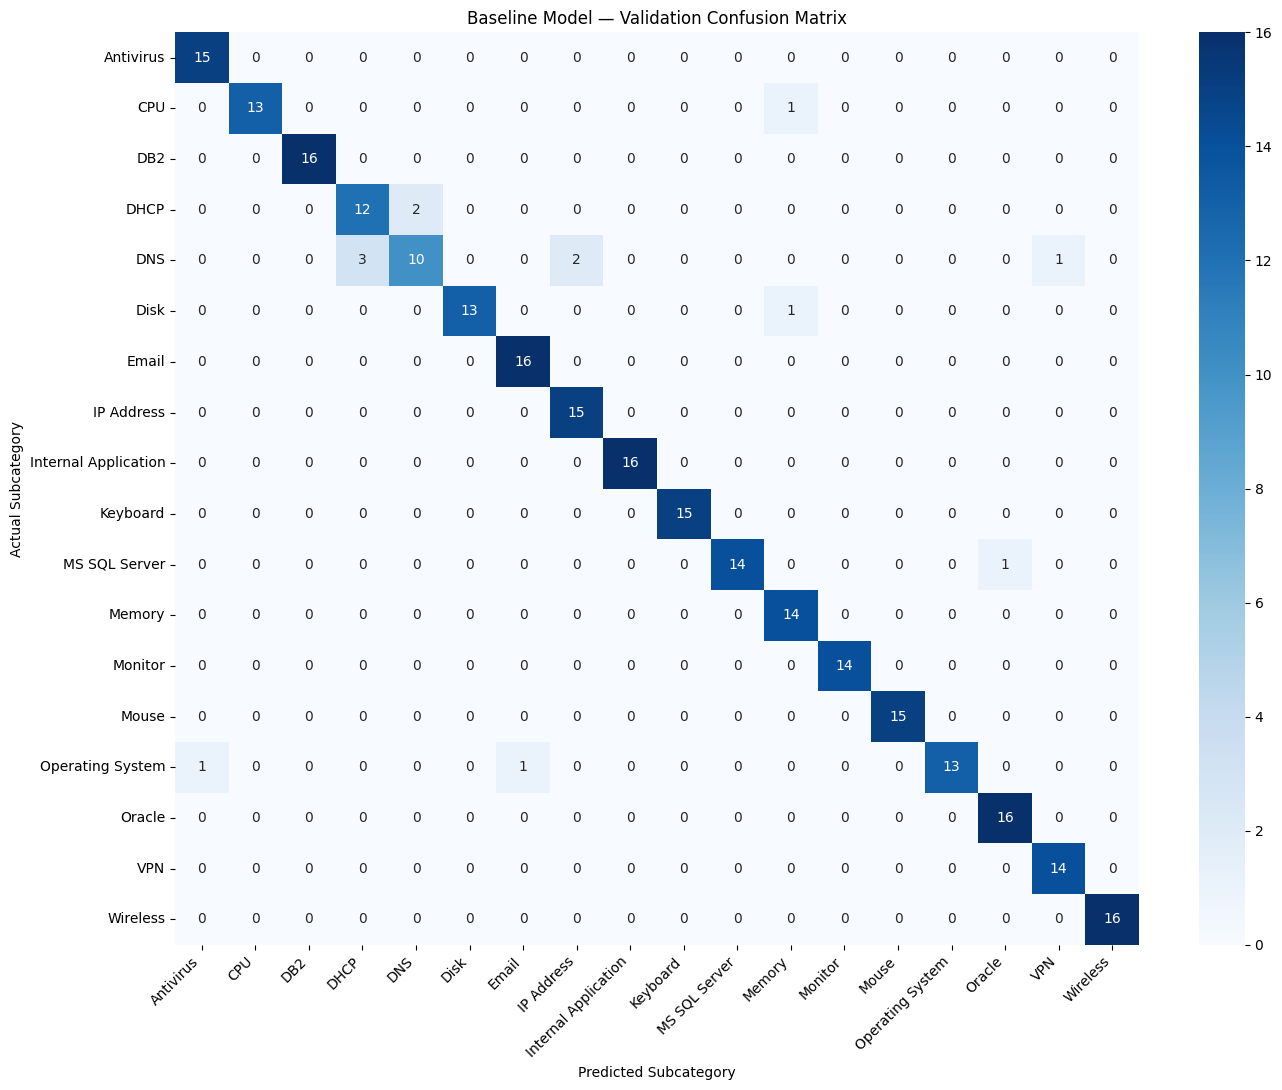

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Get all subcategory names
labels = sorted(val_df["Subcategory"].unique())

# Calculate confusion matrix
cm = confusion_matrix(
    val_df["Subcategory"],
    val_predictions,
    labels=labels
)

# Visualize
plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Subcategory")
plt.ylabel("Actual Subcategory")
plt.title("Baseline Model — Validation Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [25]:
errors_df = val_df.copy()

errors_df["Predicted"] = val_predictions

errors_df = errors_df[
    errors_df["Subcategory"] != errors_df["Predicted"]
]

display(
    errors_df[
        ["Text", "Language", "Subcategory", "Predicted"]
    ]
)

,Text,Language,Subcategory,Predicted
1182,I suspect there's a problem with the way my ro...,en,DNS,DHCP
1066,I'm unable to access network shares from my co...,en,DHCP,DNS
1192,I'm encountering strange IP conflicts within m...,en,DNS,IP Address
1063,I'm getting 'network cable unplugged' errors o...,en,DHCP,DNS
551,"I'm having trouble accessing my files, and it ...",en,Disk,Memory
1191,The network speed seems to be much slower than...,en,DNS,DHCP
1149,Il mio provider di servizi Internet mi ha dett...,it,DNS,IP Address
317,Non riesco a trovare una soluzione al problema...,it,Operating System,Antivirus
1142,Alcuni siti web sembrano essere irraggiungibil...,it,DNS,VPN
389,The search function in the file explorer retur...,en,Operating System,Email


In [26]:
import pandas as pd
from IPython.display import display

# Show the complete text without truncation
pd.set_option("display.max_colwidth", None)

# Display all 13 incorrect predictions
display(
    errors_df[
        ["Text", "Language", "Subcategory", "Predicted"]
    ].reset_index()
)

,index,Text,Language,Subcategory,Predicted
0,1182,I suspect there's a problem with the way my router is handling network requests.,en,DNS,DHCP
1,1066,"I'm unable to access network shares from my computer, even though they were accessible yesterday.",en,DHCP,DNS
2,1192,I'm encountering strange IP conflicts within my local network.,en,DNS,IP Address
3,1063,"I'm getting 'network cable unplugged' errors on my desktop computer, even though the cables are securely connected.",en,DHCP,DNS
4,551,"I'm having trouble accessing my files, and it could be a problem with the internal memory of my device.",en,Disk,Memory
5,1191,The network speed seems to be much slower than what I'm paying for.,en,DNS,DHCP
6,1149,"Il mio provider di servizi Internet mi ha detto che ci sono problemi nella mia zona, ma non hanno fornito ulteriori dettagli.",it,DNS,IP Address
7,317,Non riesco a trovare una soluzione al problema di incompatibilità tra il mio sistema operativo e il mio antivirus.,it,Operating System,Antivirus
8,1142,"Alcuni siti web sembrano essere irraggiungibili da casa mia, ma funzionano da altri luoghi.",it,DNS,VPN
9,389,The search function in the file explorer returns inaccurate or incomplete results.,en,Operating System,Email


In [27]:
# Tickets requiring further label review
review_ids = [1192, 1063, 551, 317, 1617]

review_df = errors_df.loc[
    errors_df.index.isin(review_ids),
    ["Text", "Subcategory", "Predicted"]
].copy()

review_df["Review_Status"] = "Needs manual review"

display(review_df)

,Text,Subcategory,Predicted,Review_Status
1192,I'm encountering strange IP conflicts within my local network.,DNS,IP Address,Needs manual review
1063,"I'm getting 'network cable unplugged' errors on my desktop computer, even though the cables are securely connected.",DHCP,DNS,Needs manual review
551,"I'm having trouble accessing my files, and it could be a problem with the internal memory of my device.",Disk,Memory,Needs manual review
317,Non riesco a trovare una soluzione al problema di incompatibilità tra il mio sistema operativo e il mio antivirus.,Operating System,Antivirus,Needs manual review
1617,Le query che funzionavano bene in precedenza ora restituiscono risultati errati.,MS SQL Server,Oracle,Needs manual review


fine-tunning

In [28]:
import torch
import transformers

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)

print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

PyTorch version: 2.14.1
Transformers version: 4.51.3
MPS available: True
Device: mps


In [29]:
import sys
import importlib.metadata as md
import torch

print("Python:", sys.version)
print("Python executable:", sys.executable)

for package in ["transformers", "huggingface-hub", "tokenizers", "torch"]:
    print(package, md.version(package))

print("MPS available:", torch.backends.mps.is_available())

Python: 3.13.9 (v3.13.9:8183fa5e3f7, Oct 14 2025, 10:27:13) [Clang 16.0.0 (clang-1600.0.26.6)]
Python executable: /usr/local/bin/python3
transformers 4.51.3
huggingface-hub 0.36.2
tokenizers 0.21.4
torch 2.14.1
MPS available: True


In [30]:
label_names = sorted(df["Subcategory"].unique())

label2id = {
    label: idx
    for idx, label in enumerate(label_names)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

print("Number of categories:", len(label_names))
print("DB2 label:", label2id["DB2"])
print("Wireless label:", label2id["Wireless"])

Number of categories: 18
DB2 label: 2
Wireless label: 17


In [31]:
from transformers import AutoModelForSequenceClassification

model_name = "FacebookAI/xlm-roberta-base"

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully!")
print("Number of output classes:", model.config.num_labels)

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded successfully!
Number of output classes: 18


In [32]:
import transformers
import huggingface_hub

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("All imports successful!")

Transformers: 4.51.3
Hugging Face Hub: 0.36.2
All imports successful!


In [33]:
import pandas as pd
import numpy as np
import torch

from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

PyTorch: 2.14.1
MPS available: True


In [34]:
file_path = hf_hub_download(
    repo_id="Noise144/ticket_classification_IT_EN",
    filename="Dataset_ticket.xlsx",
    repo_type="dataset"
)

df = pd.read_excel(file_path)

print("Dataset:", df.shape)

Dataset: (1800, 3)


In [35]:
label_names = sorted(df["Subcategory"].unique())

label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

df["label"] = df["Subcategory"].map(label2id)

langid.set_languages(["it", "en"])
df["Language"] = df["Text"].apply(lambda x: langid.classify(x)[0])

df["stratify_label"] = df["Subcategory"] + "_" + df["Language"]

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["stratify_label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["stratify_label"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1260
Validation: 270
Test: 270


In [36]:
model_name = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=18,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully!")

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded successfully!


In [37]:
class TicketDataset(Dataset):
    def __init__(self, dataframe, tokenizer):
        self.texts = dataframe["Text"].tolist()
        self.labels = dataframe["label"].tolist()
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=128
        )
        encoding["labels"] = int(self.labels[idx])
        return encoding


train_dataset = TicketDataset(train_df, tokenizer)
val_dataset = TicketDataset(val_df, tokenizer)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 1260
Validation: 270


In [38]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }

In [39]:
training_args = TrainingArguments(
    output_dir="./xlmr_ticket_classifier",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=20,
    report_to="none",
    seed=42,
    data_seed=42,
    dataloader_num_workers=0
)

In [40]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer ready!")

Trainer ready!


In [41]:
trainer.train()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.073500,1.489477,0.866667,0.849921
2,0.985000,0.594616,0.925926,0.922711
3,0.689800,0.426402,0.933333,0.930504


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=474, training_loss=1.5067986073876232, metrics={'train_runtime': 374.6051, 'train_samples_per_second': 10.091, 'train_steps_per_second': 1.265, 'total_flos': 59282502595776.0, 'train_loss': 1.5067986073876232, 'epoch': 3.0})

In [42]:
results = trainer.evaluate()

print("Validation Accuracy:", round(results["eval_accuracy"], 4))
print("Validation Macro-F1:", round(results["eval_macro_f1"], 4))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Validation Accuracy: 0.9333
Validation Macro-F1: 0.9305


In [43]:
save_path = "./final_xlmr_ticket_model"

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved!")

Model saved!


In [44]:
import numpy as np

from sklearn.metrics import classification_report

# Get predictions on validation data
val_predictions = trainer.predict(val_dataset)

# Convert logits into predicted class IDs
y_pred = np.argmax(
    val_predictions.predictions,
    axis=-1
)

# Get correct labels
y_true = val_predictions.label_ids

# Generate classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(label_names))),
    target_names=label_names,
    digits=4,
    zero_division=0
)

print(report)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


                      precision    recall  f1-score   support

           Antivirus     0.9333    0.9333    0.9333        15
                 CPU     1.0000    1.0000    1.0000        14
                 DB2     0.9375    0.9375    0.9375        16
                DHCP     0.7059    0.8571    0.7742        14
                 DNS     1.0000    0.5000    0.6667        16
                Disk     1.0000    0.9286    0.9630        14
               Email     1.0000    1.0000    1.0000        16
          IP Address     0.8824    1.0000    0.9375        15
Internal Application     0.9412    1.0000    0.9697        16
            Keyboard     1.0000    1.0000    1.0000        15
       MS SQL Server     0.9333    0.9333    0.9333        15
              Memory     0.8750    1.0000    0.9333        14
             Monitor     1.0000    1.0000    1.0000        14
               Mouse     1.0000    1.0000    1.0000        15
    Operating System     1.0000    0.7333    0.8462        15
       

In [46]:
print("Best checkpoint:", trainer.state.best_model_checkpoint)

print("Best validation metric:", trainer.state.best_metric)

print("Current model evaluation:")
print(trainer.evaluate(val_dataset))


Best checkpoint: ./xlmr_ticket_classifier/checkpoint-474
Best validation metric: 0.9305044513408744
Current model evaluation:


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 0.42640233039855957, 'eval_accuracy': 0.9333333333333333, 'eval_macro_f1': 0.9305044513408744, 'eval_runtime': 0.7604, 'eval_samples_per_second': 355.064, 'eval_steps_per_second': 44.712, 'epoch': 3.0}
